<a href="https://colab.research.google.com/github/hsamisha/EDA-E-Commerce-sales-Project/blob/main/Amisha_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# E-COMMERCE SALES DATA ANALYSIS
# END-TO-END EXPLORATORY DATA ANALYSIS
# ============================================================

# ============================================================
# STEP 1 — IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:


# STEP 2: AUTOMATICALLY DOWNLOAD DATASET FROM GOOGLE DRIVE

!pip -q install gdown

import os
import zipfile
import pandas as pd
import gdown

# Your Google Drive file ID
file_id = "1e9Aj_sZ5PjXb_zsoM5Sv3a1uinABgcGp"

# File locations
zip_path = "/content/sales_dataset.zip"
extract_path = "/content/sales_data"

# Download automatically
url = f"https://drive.google.com/uc?id={file_id}"

downloaded_file = gdown.download(
    url=url,
    output=zip_path,
    quiet=False,
    fuzzy=True
)

if not downloaded_file or not os.path.exists(zip_path):
    raise RuntimeError(
        "Download failed. Check the Google Drive sharing permissions."
    )

# Extract ZIP
if not zipfile.is_zipfile(zip_path):
    raise ValueError(
        "The downloaded file is not a ZIP. "
        "Check that your Drive link points to the ZIP dataset."
    )

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

# Find CSV files
csv_files = []

for root, dirs, filenames in os.walk(extract_path):
    for name in filenames:
        if name.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, name))

print("CSV files found:")
for path in csv_files:
    print(path)

if not csv_files:
    raise FileNotFoundError("No CSV file found inside the ZIP.")

# Select sales_dataset.csv if available
file_path = next(
    (
        p for p in csv_files
        if os.path.basename(p).lower() == "sales_dataset.csv"
    ),
    csv_files[0]
)

# Load dataset
df = pd.read_csv(file_path)

print("\nDataset loaded successfully!")
print("Selected file:", file_path)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())


Downloading...
From: https://drive.google.com/uc?id=1e9Aj_sZ5PjXb_zsoM5Sv3a1uinABgcGp
To: /content/sales_dataset.zip
100%|██████████| 7.84M/7.84M [00:00<00:00, 271MB/s]


CSV files found:
/content/sales_data/sales_dataset/sales_dataset.csv

Dataset loaded successfully!
Selected file: /content/sales_data/sales_dataset/sales_dataset.csv
Rows: 128949
Columns: 23


/tmp/ipykernel_687/2334354598.py:67: DtypeWarning: Columns (22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,Size,ASIN,Courier Status,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,S,B09KXVBD7Z,NaN,0,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,3XL,B09K3WFS32,Shipped,1,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,XL,B07WV4JV4D,Shipped,1,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,L,B099NRCT7B,NaN,0,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,3XL,B098714BZP,Shipped,1,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN


In [ ]:

# ============================================================
# STEP 3: DATA CLEANING AND INITIAL EXPLORATION
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# Check that Step 2 loaded the dataset
if "df" not in globals():
    raise ValueError("Please run Step 2 first to load the dataset.")

# Standardize column names
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[\s\-]+", "_", regex=True)
    .str.replace(r"[^a-z0-9_]", "", regex=True)
)

print("STEP 3: DATASET OVERVIEW")
print("=" * 50)

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

# Check missing values
print("\nMissing values:")
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / max(len(df), 1) * 100
    ).round(2)
})
display(missing_report.sort_values(
    "Missing_Count", ascending=False
))

# Check duplicate rows
duplicate_count = df.duplicated().sum()
print("\nDuplicate rows:", duplicate_count)

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

print("\nDuplicate rows removed:", duplicate_count)
print("Dataset shape after cleaning:", df.shape)

print("\nSTEP 3 COMPLETED SUCCESSFULLY!")


STEP 3: DATASET OVERVIEW

Dataset shape: (128949, 23)

Column names:
['order_id', 'date', 'status', 'fulfilment', 'sales_channel', 'ship_service_level', 'style', 'sku', 'category', 'size', 'asin', 'courier_status', 'qty', 'currency', 'amount', 'ship_city', 'ship_state', 'ship_postal_code', 'ship_country', 'promotion_ids', 'b2b', 'fulfilled_by', 'unnamed_22']

First 5 rows:


,order_id,date,status,fulfilment,sales_channel,ship_service_level,style,sku,category,size,asin,courier_status,qty,currency,amount,ship_city,ship_state,ship_postal_code,ship_country,promotion_ids,b2b,fulfilled_by,unnamed_22
0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,S,B09KXVBD7Z,NaN,0,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,3XL,B09K3WFS32,Shipped,1,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,XL,B07WV4JV4D,Shipped,1,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,L,B099NRCT7B,NaN,0,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,3XL,B098714BZP,Shipped,1,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN



Data types:
order_id               object
date                   object
status                 object
fulfilment             object
sales_channel          object
ship_service_level     object
style                  object
sku                    object
category               object
size                   object
asin                   object
courier_status         object
qty                     int64
currency               object
amount                float64
ship_city              object
ship_state             object
ship_postal_code      float64
ship_country           object
promotion_ids          object
b2b                      bool
fulfilled_by           object
unnamed_22             object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128949 entries, 0 to 128948
Data columns (total 23 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   order_id            128949 non-null  object 


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,128949,120352,403-4984515-8861958,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,128949,91,05-03-2022,2085,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,128949,13,Shipped,77767,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fulfilment,128949,2,Amazon,89679,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sales_channel,128949,2,Amazon.in,128825,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ship_service_level,128949,2,Expedited,88596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
style,128949,1377,JNE3797,4224,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sku,128949,7195,JNE3797-KR-L,773,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,128949,9,Set,50275,NaN,NaN,NaN,NaN,NaN,NaN,NaN
size,128949,11,M,22705,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


,Missing_Count,Missing_Percentage
fulfilled_by,89679,69.55
promotion_ids,49142,38.11
unnamed_22,49041,38.03
currency,7794,6.04
amount,7794,6.04
courier_status,6871,5.33
ship_city,33,0.03
ship_state,33,0.03
ship_postal_code,33,0.03
ship_country,33,0.03



Duplicate rows: 6

Duplicate rows removed: 6
Dataset shape after cleaning: (128943, 23)

STEP 3 COMPLETED SUCCESSFULLY!


In [ ]:

# ============================================================
# STEP 4: DATA TYPE CONVERSION AND MISSING VALUES
# ============================================================

import pandas as pd
import numpy as np

# 1. Check actual column names
print("Available columns:")
print(df.columns.tolist())

# 2. Convert date column if available
if "date" in df.columns:
    df["date"] = pd.to_datetime(
        df["date"], errors="coerce"
    )
    print("\nDate column converted successfully.")

# 3. Convert amount to numeric
if "amount" in df.columns:
    df["amount"] = pd.to_numeric(
        df["amount"].astype(str)
        .str.replace(",", "", regex=False)
        .str.replace("₹", "", regex=False)
        .str.strip(),
        errors="coerce"
    )
    print("Amount column converted successfully.")

# 4. Convert quantity to numeric
if "qty" in df.columns:
    df["qty"] = pd.to_numeric(
        df["qty"].astype(str)
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce"
    )
    print("Quantity column converted successfully.")

# 5. Handle missing amount values
if "amount" in df.columns:
    missing_amount = df["amount"].isna().sum()

    if df["amount"].notna().any():
        median_amount = df["amount"].median()
        df["amount"] = df["amount"].fillna(median_amount)

    print("\nMissing amount values before filling:",
          missing_amount)
    print("Missing amount values remaining:",
          df["amount"].isna().sum())

# 6. Check quantity issues without changing them
if "qty" in df.columns:
    print("\nMissing quantity values:",
          df["qty"].isna().sum())

    print("Zero or negative quantities:",
          (df["qty"] <= 0).sum())

# 7. Display updated data types
print("\nUpdated data types:")
print(df.dtypes)

print("\nFirst 5 cleaned rows:")
display(df.head())

print("\nSTEP 4 COMPLETED SUCCESSFULLY!")


Available columns:
['order_id', 'date', 'status', 'fulfilment', 'sales_channel', 'ship_service_level', 'style', 'sku', 'category', 'size', 'asin', 'courier_status', 'qty', 'currency', 'amount', 'ship_city', 'ship_state', 'ship_postal_code', 'ship_country', 'promotion_ids', 'b2b', 'fulfilled_by', 'unnamed_22']

Date column converted successfully.


/tmp/ipykernel_687/419338047.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(


Amount column converted successfully.
Quantity column converted successfully.

Missing amount values before filling: 7791
Missing amount values remaining: 0

Missing quantity values: 0
Zero or negative quantities: 12807

Updated data types:
order_id                      object
date                  datetime64[ns]
status                        object
fulfilment                    object
sales_channel                 object
ship_service_level            object
style                         object
sku                           object
category                      object
size                          object
asin                          object
courier_status                object
qty                            int64
currency                      object
amount                       float64
ship_city                     object
ship_state                    object
ship_postal_code             float64
ship_country                  object
promotion_ids                 object
b2b                

,order_id,date,status,fulfilment,sales_channel,ship_service_level,style,sku,category,size,asin,courier_status,qty,currency,amount,ship_city,ship_state,ship_postal_code,ship_country,promotion_ids,b2b,fulfilled_by,unnamed_22
0,405-8078784-5731545,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,S,B09KXVBD7Z,NaN,0,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,171-9198151-1101146,2022-04-30,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,3XL,B09K3WFS32,Shipped,1,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,404-0687676-7273146,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,XL,B07WV4JV4D,Shipped,1,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,403-9615377-8133951,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,L,B099NRCT7B,NaN,0,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,407-1069790-7240320,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,3XL,B098714BZP,Shipped,1,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN



STEP 4 COMPLETED SUCCESSFULLY!


In [ ]:

# ============================================================
# STEP 5: BUSINESS KPIs
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

print("=" * 50)
print("         E-COMMERCE BUSINESS KPIs")
print("=" * 50)

# 1. Total Orders
if "order_id" in df.columns:
    total_orders = df["order_id"].nunique()
    print(f"Total Unique Orders: {total_orders:,}")
else:
    total_orders = None
    print("Total Orders: order_id column not available")

# 2. Total Sales
if "amount" in df.columns:
    total_sales = df["amount"].sum()
    print(f"Total Sales: {total_sales:,.2f}")
else:
    total_sales = None
    print("Total Sales: amount column not available")

# 3. Total Quantity Sold
if "qty" in df.columns:
    total_quantity = df["qty"].sum()
    print(f"Total Quantity Sold: {total_quantity:,.0f}")
else:
    total_quantity = None
    print("Total Quantity: qty column not available")

# 4. Average Order Value
if "order_id" in df.columns and "amount" in df.columns:
    order_amounts = (
        df.dropna(subset=["order_id"])
        .groupby("order_id")["amount"]
        .sum()
    )

    average_order_value = (
        order_amounts.mean()
        if not order_amounts.empty
        else np.nan
    )

    print(
        f"Average Order Value: {average_order_value:,.2f}"
        if pd.notna(average_order_value)
        else "Average Order Value: Not available"
    )

elif "amount" in df.columns:
    average_order_value = df["amount"].mean()
    print(
        f"Average Record Amount: {average_order_value:,.2f}"
    )
else:
    average_order_value = np.nan
    print("Average Order Value: Not available")

# Display KPI table
kpi_table = pd.DataFrame({
    "KPI": [
        "Total Unique Orders",
        "Total Sales",
        "Total Quantity Sold",
        "Average Order Value"
    ],
    "Value": [
        total_orders,
        total_sales,
        total_quantity,
        average_order_value
    ]
})

print("\nKPI SUMMARY TABLE")
display(kpi_table)

print("\nSTEP 5 COMPLETED SUCCESSFULLY!")


         E-COMMERCE BUSINESS KPIs
Total Unique Orders: 120,352
Total Sales: 83,286,092.94
Total Quantity Sold: 116,648
Average Order Value: 692.02

KPI SUMMARY TABLE


,KPI,Value
0,Total Unique Orders,1.203520e+05
1,Total Sales,8.328609e+07
2,Total Quantity Sold,1.166480e+05
3,Average Order Value,6.920208e+02



STEP 5 COMPLETED SUCCESSFULLY!


In [ ]:

# FORMAT KPI TABLE FOR BETTER READABILITY

kpi_table = pd.DataFrame({
    "KPI": [
        "Total Unique Orders",
        "Total Sales",
        "Total Quantity Sold",
        "Average Order Value"
    ],
    "Value": [
        f"{total_orders:,}",
        f"{total_sales:,.2f}",
        f"{total_quantity:,}",
        f"{average_order_value:,.2f}"
    ]
})

display(kpi_table)


,KPI,Value
0,Total Unique Orders,"120,352"
1,Total Sales,"83,286,092.94"
2,Total Quantity Sold,"116,648"
3,Average Order Value,692.02


MONTHLY SALES SUMMARY


,date,amount
0,2022-03-01,107128.85
1,2022-04-01,30646525.96
2,2022-05-01,27735050.75
3,2022-06-01,24797387.38


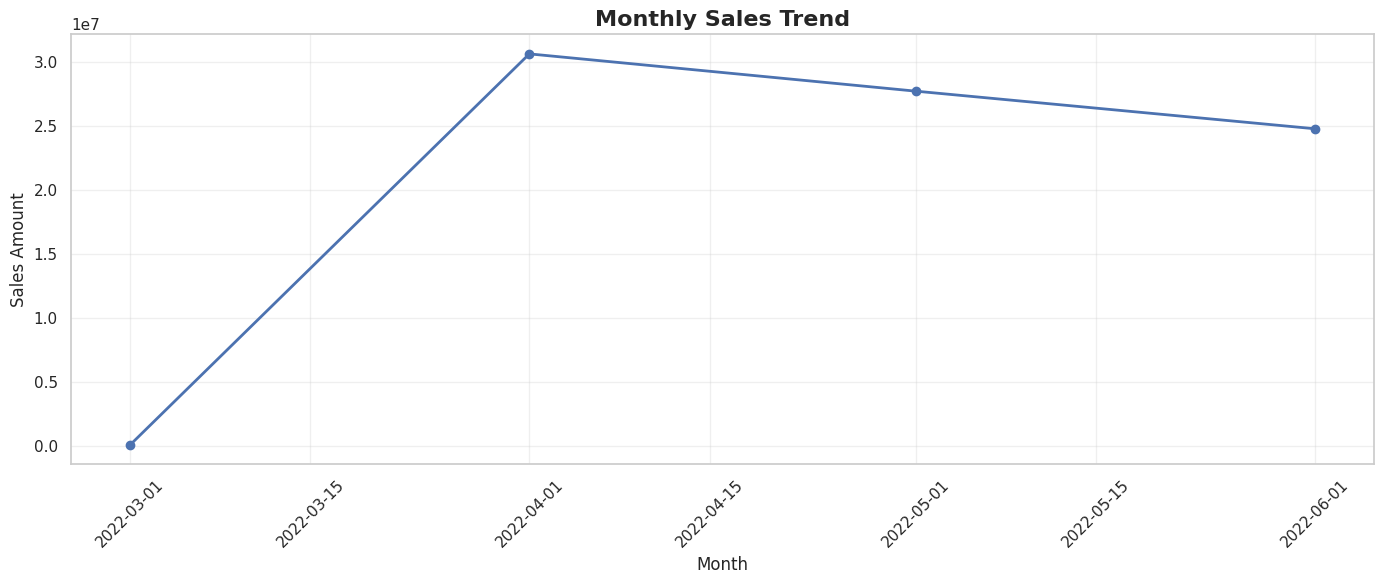

Highest Sales Month: April 2022
Highest Sales Amount: 30,646,525.96
Lowest Sales Month: March 2022
Lowest Sales Amount: 107,128.85
STEP 6 COMPLETED!


In [ ]:

# ============================================================
# STEP 6: MONTHLY SALES TREND
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

if "date" not in df.columns:
    print("Date column not found. Available columns:")
    print(df.columns.tolist())

else:
    monthly_df = df.dropna(subset=["date"]).copy()

    monthly_sales = (
        monthly_df.groupby(
            monthly_df["date"].dt.to_period("M")
        )["amount"]
        .sum()
        .reset_index()
    )

    monthly_sales["date"] = (
        monthly_sales["date"].dt.to_timestamp()
    )

    print("MONTHLY SALES SUMMARY")
    display(monthly_sales)

    if not monthly_sales.empty:
        plt.figure(figsize=(14, 6))

        plt.plot(
            monthly_sales["date"],
            monthly_sales["amount"],
            marker="o",
            linewidth=2
        )

        plt.title(
            "Monthly Sales Trend",
            fontsize=16,
            fontweight="bold"
        )
        plt.xlabel("Month")
        plt.ylabel("Sales Amount")
        plt.xticks(rotation=45)
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

        highest = monthly_sales.loc[
            monthly_sales["amount"].idxmax()
        ]

        lowest = monthly_sales.loc[
            monthly_sales["amount"].idxmin()
        ]

        print(
            "Highest Sales Month:",
            highest["date"].strftime("%B %Y")
        )
        print(
            f"Highest Sales Amount: "
            f"{highest['amount']:,.2f}"
        )
        print(
            "Lowest Sales Month:",
            lowest["date"].strftime("%B %Y")
        )
        print(
            f"Lowest Sales Amount: "
            f"{lowest['amount']:,.2f}"
        )

    else:
        print("No valid dates available for monthly analysis.")

print("STEP 6 COMPLETED!")


SALES BY PRODUCT CATEGORY


,category,Total Sales
0,Set,41154789.67
1,kurta,23204584.70
2,Western Dress,11694003.69
3,Top,5623727.30
4,Ethnic Dress,830292.66
5,Blouse,485633.18
6,Bottom,162767.98
7,Saree,129378.76
8,Dupatta,915.00


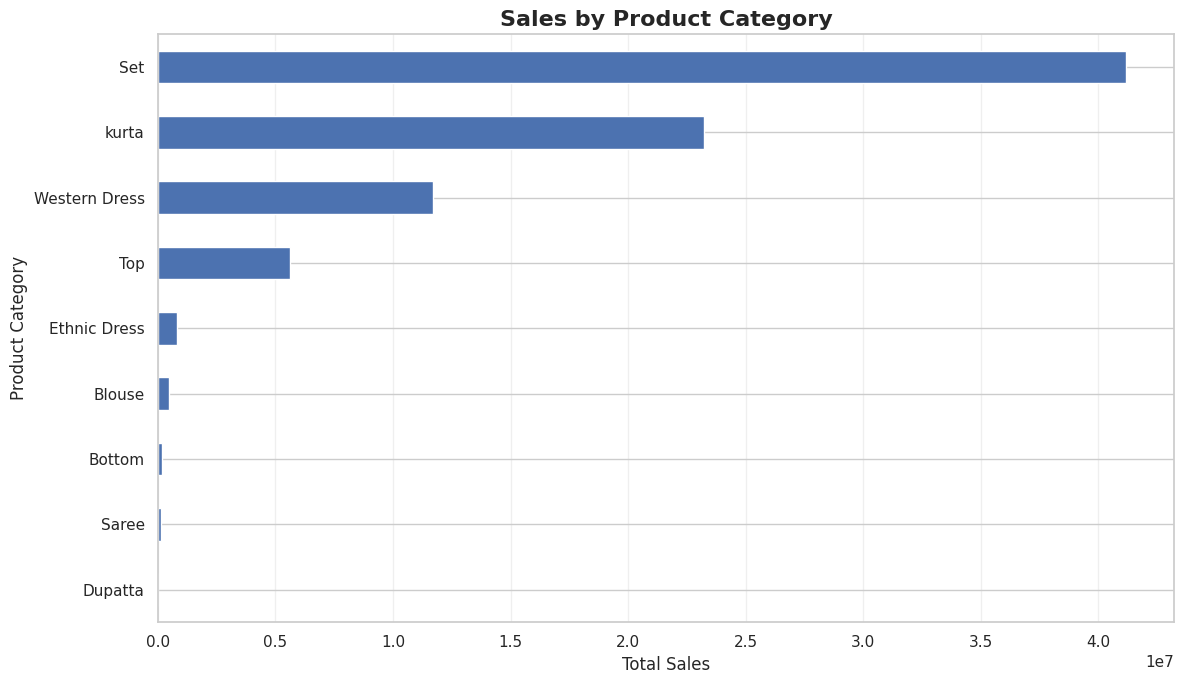


KEY FINDINGS
Highest-Sales Category: Set
Highest Category Sales: 41,154,789.67
Lowest-Sales Category: Dupatta
Lowest Category Sales: 915.00

CATEGORY SALES CONTRIBUTION (%)


,category,Sales Contribution (%)
0,Set,49.41
1,kurta,27.86
2,Western Dress,14.04
3,Top,6.75
4,Ethnic Dress,1.00
5,Blouse,0.58
6,Bottom,0.20
7,Saree,0.16
8,Dupatta,0.00



STEP 7 COMPLETED!


In [ ]:

# ============================================================
# STEP 7: PRODUCT CATEGORY SALES ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

if "category" not in df.columns:
    print("Category column not found.")
    print("Available columns:", df.columns.tolist())

else:
    # Calculate sales by category
    category_sales = (
        df.groupby("category", dropna=False)["amount"]
        .sum()
        .sort_values(ascending=False)
    )

    print("SALES BY PRODUCT CATEGORY")
    display(category_sales.reset_index(name="Total Sales"))

    # Bar chart
    plot_data = category_sales.dropna().sort_values()

    if not plot_data.empty:
        plt.figure(figsize=(12, 7))

        plot_data.plot(kind="barh")

        plt.title(
            "Sales by Product Category",
            fontsize=16,
            fontweight="bold"
        )
        plt.xlabel("Total Sales")
        plt.ylabel("Product Category")
        plt.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.show()

        # Highest and lowest sales categories
        valid_sales = category_sales.dropna()

        if not valid_sales.empty:
            print("\nKEY FINDINGS")
            print("Highest-Sales Category:", valid_sales.idxmax())
            print(f"Highest Category Sales: {valid_sales.max():,.2f}")

            print("Lowest-Sales Category:", valid_sales.idxmin())
            print(f"Lowest Category Sales: {valid_sales.min():,.2f}")

            # Percentage contribution
            total_category_sales = valid_sales.sum()

            if total_category_sales != 0:
                category_percentage = (
                    valid_sales / total_category_sales * 100
                ).round(2)

                print("\nCATEGORY SALES CONTRIBUTION (%)")
                display(
                    category_percentage
                    .rename("Sales Contribution (%)")
                    .reset_index()
                )
    else:
        print("No category sales data available.")

print("\nSTEP 7 COMPLETED!")


TOP 10 PRODUCTS BY SALES


,style,Total Sales
0,JNE3797,3072027.00
1,J0230,2025460.48
2,SET268,1381363.56
3,J0341,1330982.87
4,J0003,1064253.75
5,JNE3405,942618.36
6,J0008,860914.96
7,SET345,782692.79
8,SET324,767286.82
9,JNE3800,749413.80


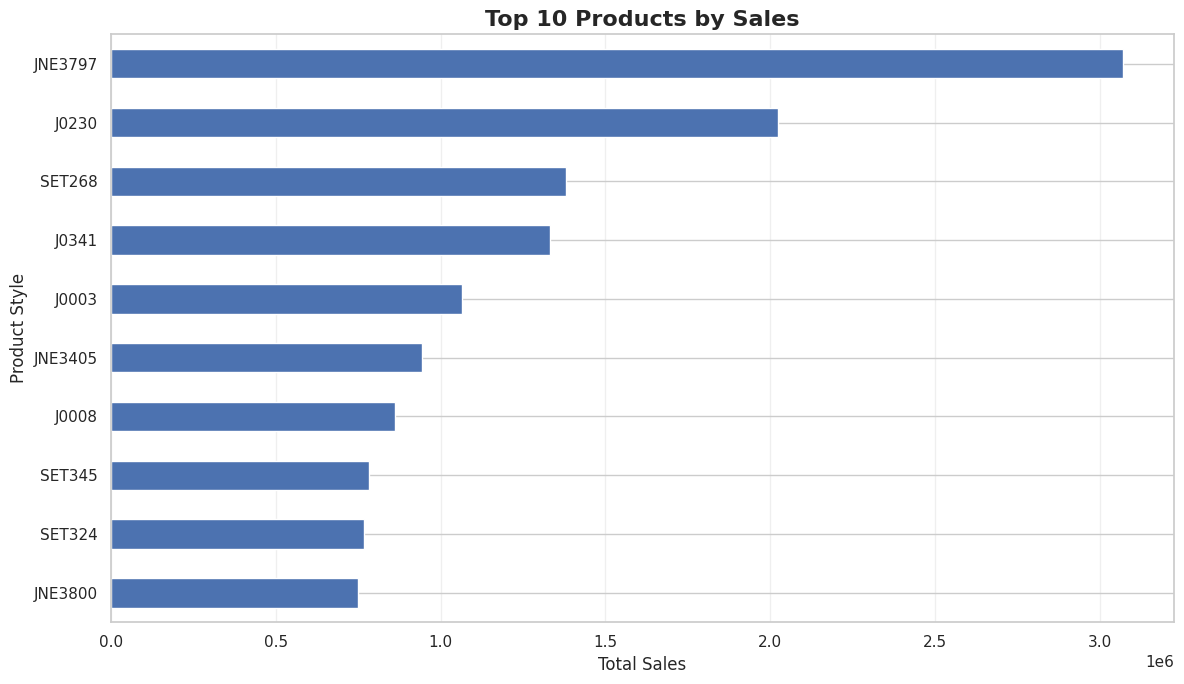


KEY FINDING
Best-Selling Product: JNE3797
Product Sales: 3,072,027.00
Top 10 products' contribution to total sales: 15.58%

STEP 8 COMPLETED!


In [ ]:

# ============================================================
# STEP 8: TOP 10 PRODUCTS BY SALES
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

if "style" not in df.columns:
    print("Product/style column not found.")
    print("Available columns:", df.columns.tolist())

else:
    # Calculate sales for each product
    product_sales = (
        df.groupby("style")["amount"]
        .sum()
        .sort_values(ascending=False)
    )

    # Select top 10 products
    top_10_products = product_sales.head(10)

    print("TOP 10 PRODUCTS BY SALES")
    display(
        top_10_products
        .rename("Total Sales")
        .reset_index()
    )

    # Plot horizontal bar chart
    if not top_10_products.empty:
        plt.figure(figsize=(12, 7))

        top_10_products.sort_values().plot(
            kind="barh"
        )

        plt.title(
            "Top 10 Products by Sales",
            fontsize=16,
            fontweight="bold"
        )
        plt.xlabel("Total Sales")
        plt.ylabel("Product Style")
        plt.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.show()

        # Best-selling product
        best_product = top_10_products.idxmax()
        best_product_sales = top_10_products.max()

        print("\nKEY FINDING")
        print("Best-Selling Product:", best_product)
        print(f"Product Sales: {best_product_sales:,.2f}")

        # Contribution to overall sales
        total_sales_value = df["amount"].sum()

        if total_sales_value != 0:
            contribution = (
                top_10_products.sum()
                / total_sales_value
                * 100
            )

            print(
                f"Top 10 products' contribution to total sales: "
                f"{contribution:.2f}%"
            )
    else:
        print("No product sales data available.")

print("\nSTEP 8 COMPLETED!")


TOP 10 STATES BY SALES


,ship_state,Total Sales
0,MAHARASHTRA,14050452.14
1,KARNATAKA,11041190.37
2,TELANGANA,7333985.65
3,UTTAR PRADESH,7231934.08
4,TAMIL NADU,6921696.11
5,DELHI,4469778.97
6,KERALA,4092192.58
7,WEST BENGAL,3758100.44
8,ANDHRA PRADESH,3446162.72
9,HARYANA,3018419.99


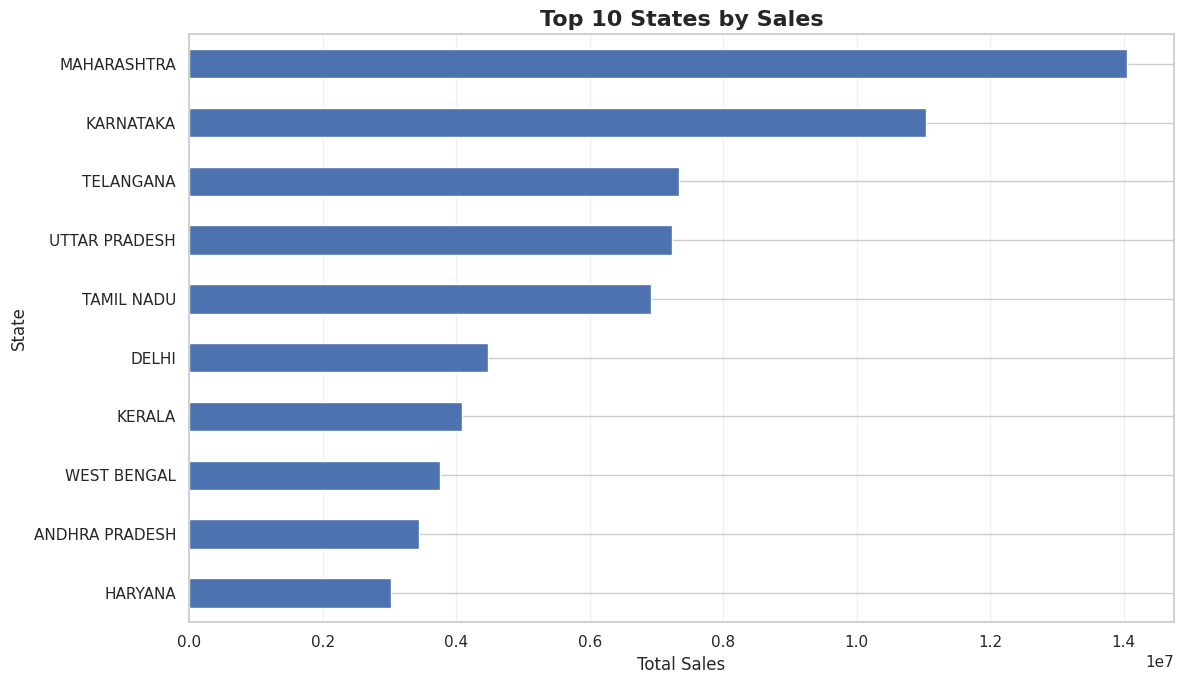


KEY FINDING
Highest-Sales State: MAHARASHTRA
Total Sales: 14,050,452.14

TOP 10 STATES' SALES CONTRIBUTION (%)


,ship_state,Sales Contribution (%)
0,MAHARASHTRA,16.87
1,KARNATAKA,13.26
2,TELANGANA,8.81
3,UTTAR PRADESH,8.69
4,TAMIL NADU,8.31
5,DELHI,5.37
6,KERALA,4.91
7,WEST BENGAL,4.51
8,ANDHRA PRADESH,4.14
9,HARYANA,3.63



STEP 9 COMPLETED!


In [ ]:

# ============================================================
# STEP 9: STATE-WISE SALES ANALYSIS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

if "ship_state" not in df.columns:
    print("State column not found.")
    print("Available columns:", df.columns.tolist())

else:
    # Calculate sales by state
    state_sales = (
        df.groupby("ship_state")["amount"]
        .sum()
        .sort_values(ascending=False)
    )

    # Select top 10 states
    top_10_states = state_sales.head(10)

    print("TOP 10 STATES BY SALES")
    display(
        top_10_states
        .rename("Total Sales")
        .reset_index()
    )

    if not top_10_states.empty:
        # Create chart
        plt.figure(figsize=(12, 7))

        top_10_states.sort_values().plot(
            kind="barh"
        )

        plt.title(
            "Top 10 States by Sales",
            fontsize=16,
            fontweight="bold"
        )
        plt.xlabel("Total Sales")
        plt.ylabel("State")
        plt.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.show()

        # Key finding
        print("\nKEY FINDING")
        print("Highest-Sales State:", state_sales.idxmax())
        print(f"Total Sales: {state_sales.max():,.2f}")

        # State-wise sales contribution
        total_state_sales = state_sales.sum()

        if total_state_sales != 0:
            state_contribution = (
                top_10_states / total_state_sales * 100
            ).round(2)

            print("\nTOP 10 STATES' SALES CONTRIBUTION (%)")
            display(
                state_contribution
                .rename("Sales Contribution (%)")
                .reset_index()
            )

    else:
        print("No state sales data available.")

print("\nSTEP 9 COMPLETED!")


TOP 10 STATES BY UNIQUE ORDERS


,ship_state,Unique Orders
0,MAHARASHTRA,20777
1,KARNATAKA,16177
2,TAMIL NADU,10517
3,TELANGANA,10402
4,UTTAR PRADESH,10060
5,DELHI,6357
6,KERALA,6105
7,WEST BENGAL,5652
8,ANDHRA PRADESH,4978
9,Gujarat,4169


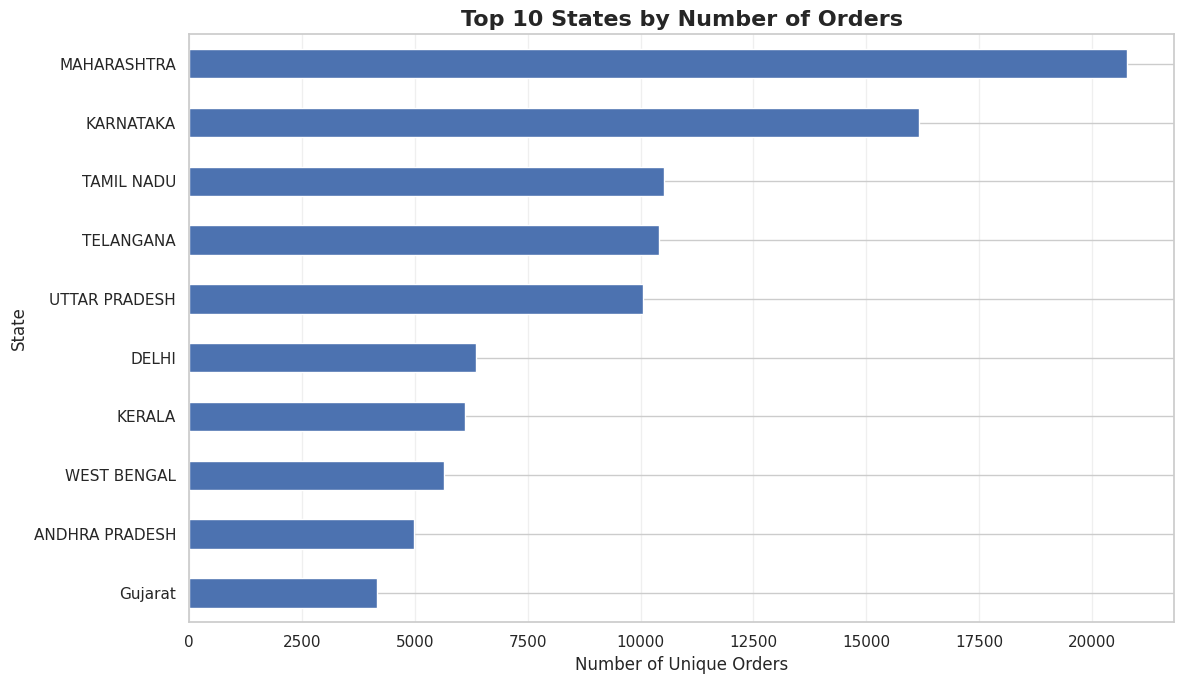


KEY FINDING
State with most orders: MAHARASHTRA
Unique orders: 20,777

STEP 10 COMPLETED!


In [ ]:

# ============================================================
# STEP 10: STATE-WISE ORDER ANALYSIS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

if "ship_state" not in df.columns or "order_id" not in df.columns:
    print("Required columns are missing.")
    print("Available columns:", df.columns.tolist())

else:
    # Count unique orders in each state
    state_orders = (
        df.groupby("ship_state")["order_id"]
        .nunique()
        .sort_values(ascending=False)
    )

    # Select top 10 states
    top_10_state_orders = state_orders.head(10)

    print("TOP 10 STATES BY UNIQUE ORDERS")
    display(
        top_10_state_orders
        .rename("Unique Orders")
        .reset_index()
    )

    if not top_10_state_orders.empty:
        # Create horizontal bar chart
        plt.figure(figsize=(12, 7))

        top_10_state_orders.sort_values().plot(
            kind="barh"
        )

        plt.title(
            "Top 10 States by Number of Orders",
            fontsize=16,
            fontweight="bold"
        )
        plt.xlabel("Number of Unique Orders")
        plt.ylabel("State")
        plt.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.show()

        # Key finding
        print("\nKEY FINDING")
        print("State with most orders:", state_orders.idxmax())
        print(f"Unique orders: {state_orders.max():,}")

print("\nSTEP 10 COMPLETED!")


SALES BY CUSTOMER TYPE


,customer_type,Total Sales
0,B2C,82677932.15
1,B2B,608160.79



CUSTOMER TYPE SUMMARY


,Total Sales,Unique Orders,Total Quantity
customer_type,,,
B2B,608160.79,794,841
B2C,82677932.15,119558,115807


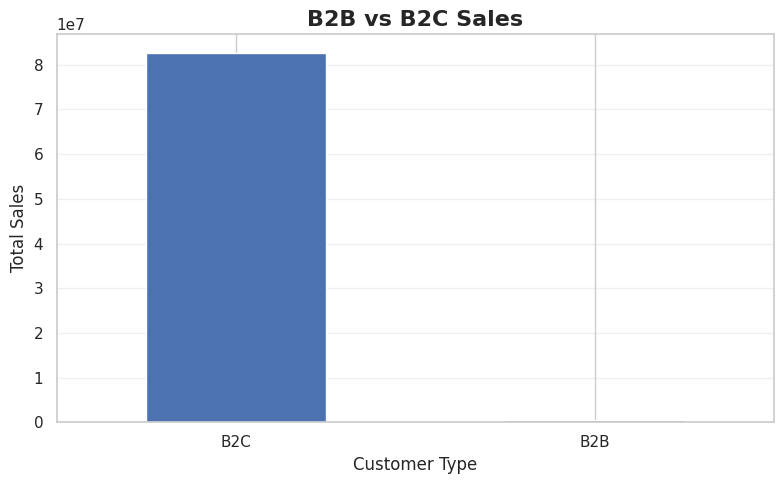


SALES CONTRIBUTION (%)


,customer_type,Sales Contribution (%)
0,B2C,99.27
1,B2B,0.73



STEP 11 COMPLETED!


In [ ]:

# ============================================================
# STEP 11: B2B VS B2C SALES ANALYSIS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

if "b2b" not in df.columns:
    print("B2B column not found.")
    print("Available columns:", df.columns.tolist())

else:
    # Standardize B2B values for display
    customer_type = df["b2b"].astype("string").str.strip().str.lower()

    df["customer_type"] = customer_type.map({
        "true": "B2B",
        "false": "B2C",
        "1": "B2B",
        "0": "B2C",
        "yes": "B2B",
        "no": "B2C"
    }).fillna("Unknown")

    # Sales by customer type
    customer_sales = (
        df.groupby("customer_type")["amount"]
        .sum()
        .sort_values(ascending=False)
    )

    print("SALES BY CUSTOMER TYPE")
    display(
        customer_sales.rename("Total Sales").reset_index()
    )

    # Orders and quantity
    summary_data = {
        "Total Sales": df.groupby("customer_type")["amount"].sum()
    }

    if "order_id" in df.columns:
        summary_data["Unique Orders"] = (
            df.groupby("customer_type")["order_id"].nunique()
        )

    if "qty" in df.columns:
        summary_data["Total Quantity"] = (
            df.groupby("customer_type")["qty"].sum()
        )

    customer_summary = pd.DataFrame(summary_data)

    print("\nCUSTOMER TYPE SUMMARY")
    display(customer_summary)

    # Chart
    if not customer_sales.empty:
        plt.figure(figsize=(8, 5))
        customer_sales.plot(kind="bar")

        plt.title(
            "B2B vs B2C Sales",
            fontsize=16,
            fontweight="bold"
        )
        plt.xlabel("Customer Type")
        plt.ylabel("Total Sales")
        plt.xticks(rotation=0)
        plt.grid(axis="y", alpha=0.3)
        plt.tight_layout()
        plt.show()

        # Sales contribution
        total_customer_sales = customer_sales.sum()

        if total_customer_sales != 0:
            contribution = (
                customer_sales / total_customer_sales * 100
            ).round(2)

            print("\nSALES CONTRIBUTION (%)")
            display(
                contribution
                .rename("Sales Contribution (%)")
                .reset_index()
            )

print("\nSTEP 11 COMPLETED!")


In [ ]:

# CHECK ORIGINAL B2B VALUES

print("Original B2B column values:")
display(df["b2b"].value_counts(dropna=False))

print("\nCustomer type mapping:")
display(
    df[["b2b", "customer_type"]]
    .drop_duplicates()
    .sort_values("customer_type")
)

print("\nSales by customer type:")
display(
    df.groupby("customer_type")["amount"]
    .agg(["count", "sum"])
)


Original B2B column values:


,count
b2b,
False,128072
True,871



Customer type mapping:


,b2b,customer_type
2,True,B2B
0,False,B2C



Sales by customer type:


,count,sum
customer_type,,
B2B,871,608160.79
B2C,128072,82677932.15


SALES BY CHANNEL


,sales_channel,Total Sales
0,Amazon.in,83211072.94
1,Non-Amazon,75020.00


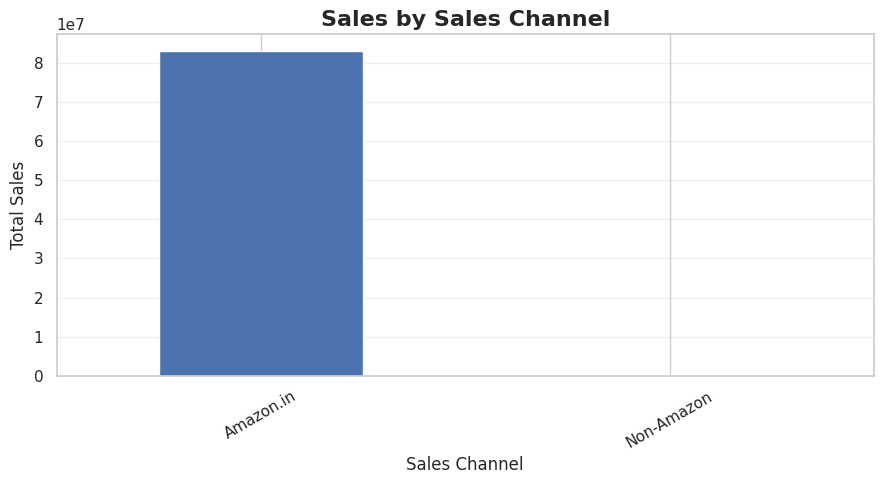


Highest-Sales Channel: Amazon.in
Sales Amount: 83,211,072.94

Sales Contribution (%)


,sales_channel,Percentage
0,Amazon.in,99.91
1,Non-Amazon,0.09



STEP 12 COMPLETED!


In [ ]:

# ============================================================
# STEP 12: SALES CHANNEL ANALYSIS
# ============================================================

import matplotlib.pyplot as plt

if "sales_channel" in df.columns:

    channel_sales = (
        df.groupby("sales_channel", dropna=False)["amount"]
        .sum()
        .sort_values(ascending=False)
    )

    print("SALES BY CHANNEL")
    display(
        channel_sales
        .rename("Total Sales")
        .reset_index()
    )

    plt.figure(figsize=(9, 5))
    channel_sales.plot(kind="bar")

    plt.title(
        "Sales by Sales Channel",
        fontsize=16,
        fontweight="bold"
    )
    plt.xlabel("Sales Channel")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=30)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    if not channel_sales.empty:
        print("\nHighest-Sales Channel:", channel_sales.idxmax())
        print(f"Sales Amount: {channel_sales.max():,.2f}")

        total = channel_sales.sum()
        if total != 0:
            print("\nSales Contribution (%)")
            display(
                (channel_sales / total * 100)
                .round(2)
                .rename("Percentage")
                .reset_index()
            )

else:
    print("Sales channel column not found.")
    print("Available columns:", df.columns.tolist())

print("\nSTEP 12 COMPLETED!")


ORDER STATUS SUMMARY


,status,Records
0,Shipped,77764
1,Shipped - Delivered to Buyer,28771
2,Cancelled,18338
3,Shipped - Returned to Seller,1953
4,Shipped - Picked Up,973
5,Pending,658
6,Pending - Waiting for Pick Up,281
7,Shipped - Returning to Seller,145
8,Shipped - Out for Delivery,35
9,Shipped - Rejected by Buyer,11


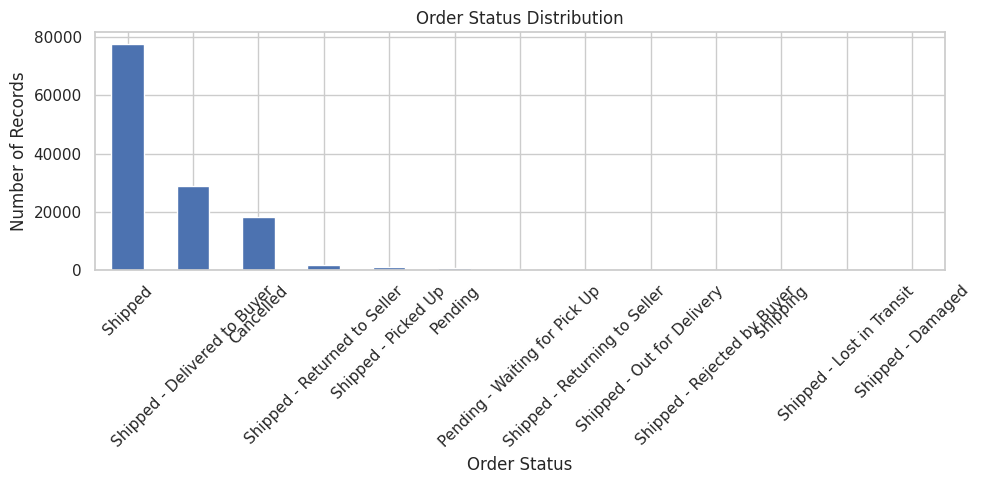


Status percentage:


,Percentage
status,
Shipped,60.31
Shipped - Delivered to Buyer,22.31
Cancelled,14.22
Shipped - Returned to Seller,1.51
Shipped - Picked Up,0.75
Pending,0.51
Pending - Waiting for Pick Up,0.22
Shipped - Returning to Seller,0.11
Shipped - Out for Delivery,0.03


STEP 13 COMPLETED!


In [ ]:

# STEP 13: ORDER STATUS ANALYSIS

import matplotlib.pyplot as plt

if "status" in df.columns:
    status_counts = df["status"].fillna("Unknown").value_counts()

    print("ORDER STATUS SUMMARY")
    display(status_counts.rename("Records").reset_index())

    status_counts.plot(kind="bar", figsize=(10, 5))
    plt.title("Order Status Distribution")
    plt.xlabel("Order Status")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    print("\nStatus percentage:")
    display((status_counts / len(df) * 100).round(2).rename("Percentage"))
else:
    print("Status column not found:", df.columns.tolist())

print("STEP 13 COMPLETED!")


Cancelled records: 18338
Cancellation rate by records: 14.22%


,category,Cancelled Records
0,Set,7337
1,kurta,7257
2,Western Dress,2125
3,Top,1276
4,Ethnic Dress,146
5,Blouse,116
6,Bottom,60
7,Saree,21


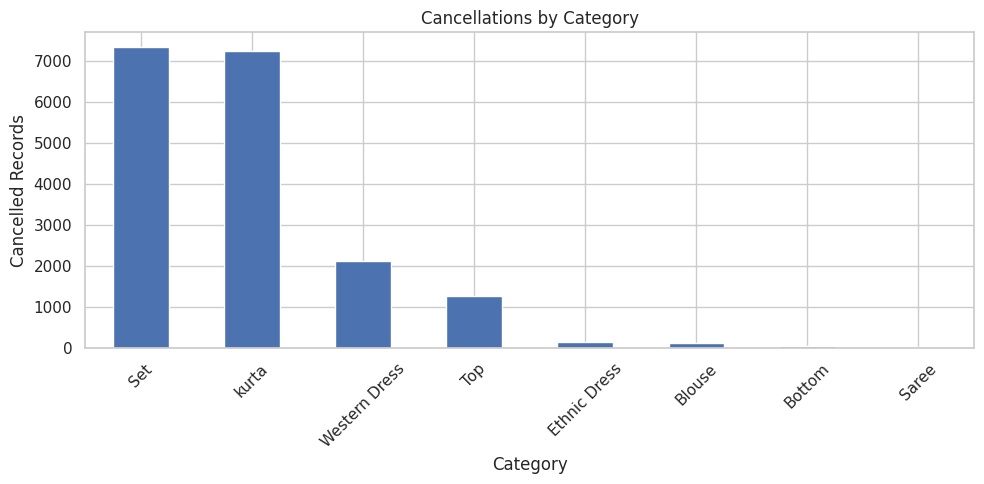

Unique cancelled orders by state:


,ship_state,Cancelled Orders
0,MAHARASHTRA,2780
1,KARNATAKA,2099
2,UTTAR PRADESH,1534
3,TELANGANA,1502
4,TAMIL NADU,1441
5,KERALA,1087
6,WEST BENGAL,848
7,DELHI,829
8,ANDHRA PRADESH,815
9,Gujarat,556


STEP 14 COMPLETED!


In [ ]:

# STEP 14: CANCELLATION ANALYSIS

if "status" in df.columns:
    cancelled_mask = df["status"].astype("string").str.contains(
        "cancel", case=False, na=False
    )
    cancelled_df = df.loc[cancelled_mask].copy()

    cancellation_rate = (
        cancelled_mask.sum() / len(df) * 100 if len(df) else 0
    )

    print("Cancelled records:", len(cancelled_df))
    print(f"Cancellation rate by records: {cancellation_rate:.2f}%")

    if "category" in df.columns:
        cancel_categories = cancelled_df["category"].value_counts()
        display(cancel_categories.rename("Cancelled Records").reset_index())

        if not cancel_categories.empty:
            cancel_categories.plot(kind="bar", figsize=(10, 5))
            plt.title("Cancellations by Category")
            plt.xlabel("Category")
            plt.ylabel("Cancelled Records")
            plt.xticks(rotation=45)
            plt.tight_layout()
            plt.show()

    if "ship_state" in df.columns and "order_id" in df.columns:
        print("Unique cancelled orders by state:")
        display(
            cancelled_df.groupby("ship_state")["order_id"]
            .nunique()
            .sort_values(ascending=False)
            .head(10)
            .rename("Cancelled Orders")
            .reset_index()
        )
else:
    print("Status column not found; cancellation analysis skipped.")

print("STEP 14 COMPLETED!")


Fulfillment record counts:


,fulfilment,Records
0,Amazon,89673
1,Merchant,39270


Sales by fulfillment method:


,fulfilment,Sales
0,Amazon,57970093.00
1,Merchant,25315999.94


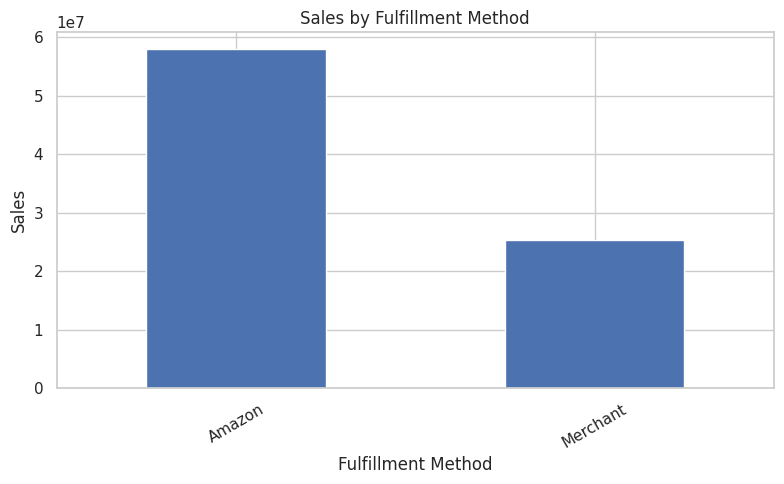

STEP 15 COMPLETED!


In [ ]:

# STEP 15: FULFILLMENT ANALYSIS

if "fulfilment" in df.columns:
    print("Fulfillment record counts:")
    display(df["fulfilment"].value_counts(dropna=False).rename("Records").reset_index())

    fulfillment_sales = df.groupby("fulfilment", dropna=False)["amount"].sum()
    print("Sales by fulfillment method:")
    display(fulfillment_sales.rename("Sales").reset_index())

    fulfillment_sales.plot(kind="bar", figsize=(8, 5))
    plt.title("Sales by Fulfillment Method")
    plt.xlabel("Fulfillment Method")
    plt.ylabel("Sales")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
else:
    print("Fulfillment column not found.")

print("STEP 15 COMPLETED!")


Sales by shipping service level:


,ship_service_level,Sales
0,Expedited,57832090.00
1,Standard,25454002.94


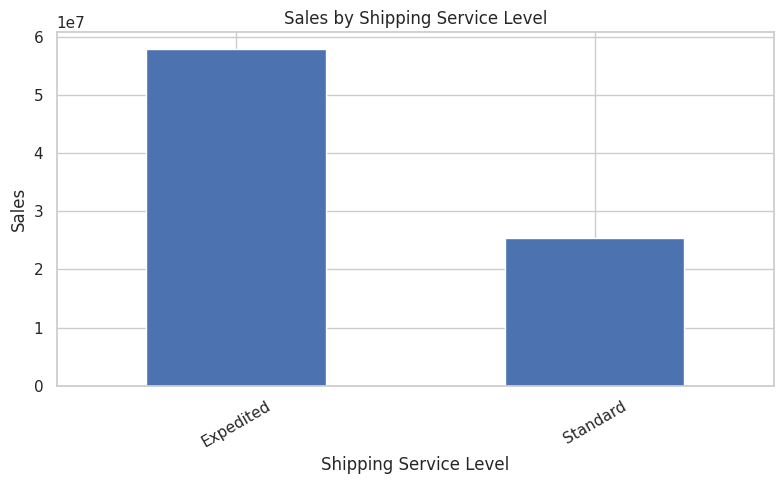

STEP 16 COMPLETED!


In [ ]:

# STEP 16: SHIPPING SERVICE LEVEL

if "ship_service_level" in df.columns:
    shipping_sales = (
        df.groupby("ship_service_level", dropna=False)["amount"]
        .sum()
        .sort_values(ascending=False)
    )

    print("Sales by shipping service level:")
    display(shipping_sales.rename("Sales").reset_index())

    shipping_sales.plot(kind="bar", figsize=(8, 5))
    plt.title("Sales by Shipping Service Level")
    plt.xlabel("Shipping Service Level")
    plt.ylabel("Sales")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
else:
    print("Shipping service level column not found.")

print("STEP 16 COMPLETED!")


Quantity sold by category:


,category,Quantity Sold
0,Set,45286
1,kurta,45048
2,Western Dress,13943
3,Top,9902
4,Ethnic Dress,1052
5,Blouse,864
6,Bottom,398
7,Saree,152
8,Dupatta,3


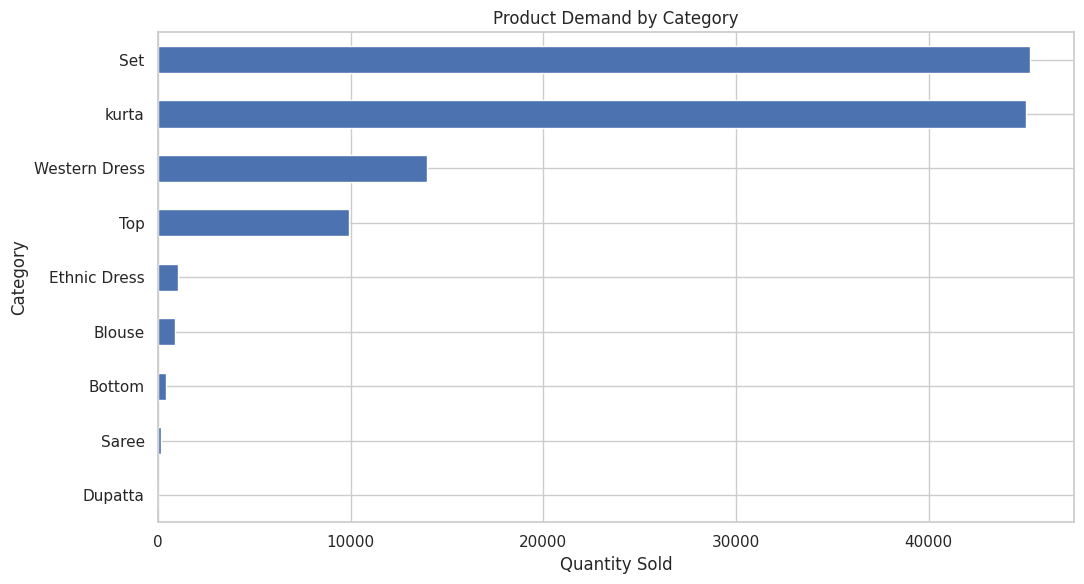

STEP 17 COMPLETED!


In [ ]:

# STEP 17: PRODUCT DEMAND BY CATEGORY

if "category" in df.columns and "qty" in df.columns:
    category_quantity = (
        df.groupby("category")["qty"]
        .sum()
        .sort_values(ascending=False)
    )

    print("Quantity sold by category:")
    display(category_quantity.rename("Quantity Sold").reset_index())

    category_quantity.sort_values().plot(kind="barh", figsize=(11, 6))
    plt.title("Product Demand by Category")
    plt.xlabel("Quantity Sold")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.show()
else:
    print("Category or quantity column not found.")

print("STEP 17 COMPLETED!")


,style,Quantity Sold
0,JNE3797,3693
1,JNE3405,2066
2,SET268,1732
3,J0230,1710
4,J0341,1472
5,J0003,1390
6,SET324,1153
7,SET345,1134
8,JNE3373,1070
9,JNE3399,972


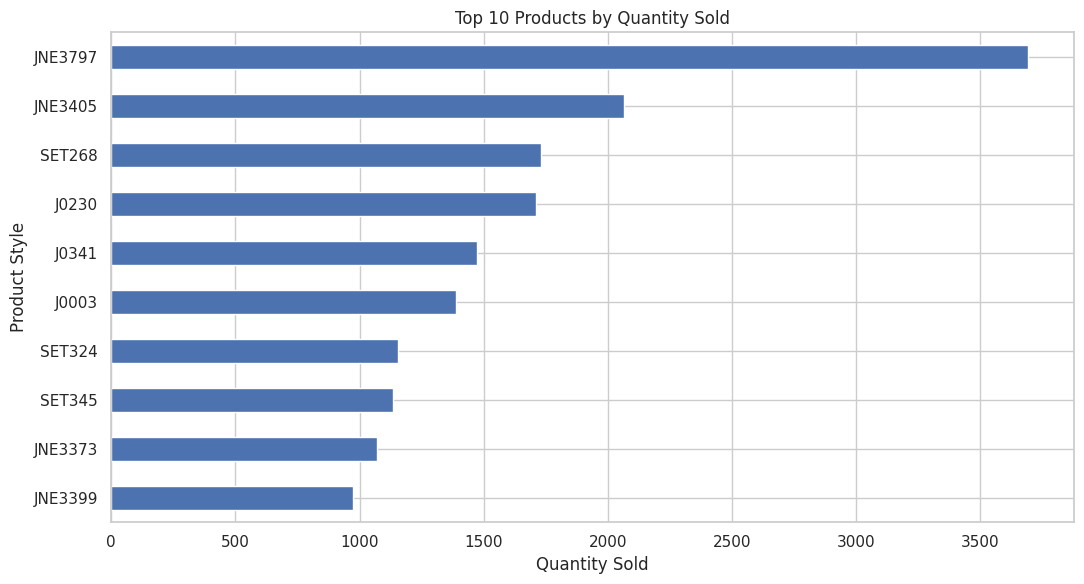

STEP 18 COMPLETED!


In [ ]:

# STEP 18: TOP 10 PRODUCTS BY QUANTITY

if "style" in df.columns and "qty" in df.columns:
    top_quantity_products = (
        df.groupby("style")["qty"]
        .sum()
        .sort_values(ascending=False)
        .head(10)
    )

    display(top_quantity_products.rename("Quantity Sold").reset_index())

    top_quantity_products.sort_values().plot(
        kind="barh", figsize=(11, 6)
    )
    plt.title("Top 10 Products by Quantity Sold")
    plt.xlabel("Quantity Sold")
    plt.ylabel("Product Style")
    plt.tight_layout()
    plt.show()
else:
    print("Product or quantity column not found.")

print("STEP 18 COMPLETED!")


Quantity sold by size:


,size,Quantity Sold
0,M,20449
1,L,19993
2,XL,18928
3,XXL,16511
4,S,15337
5,3XL,13525
6,XS,9939
7,6XL,688
8,5XL,513
9,4XL,397


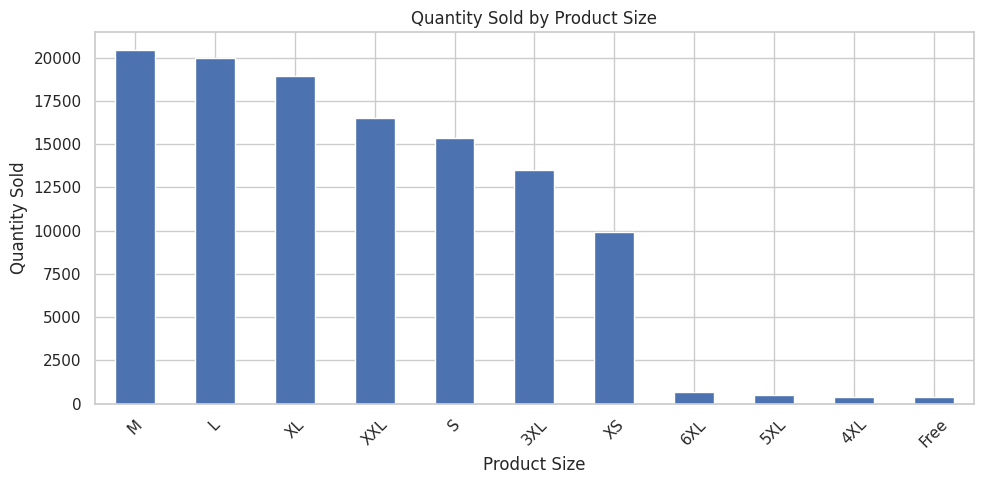

STEP 19 COMPLETED!


In [ ]:

# STEP 19: PRODUCT SIZE ANALYSIS

if "size" in df.columns and "qty" in df.columns:
    size_quantity = (
        df.groupby("size", dropna=False)["qty"]
        .sum()
        .sort_values(ascending=False)
    )

    print("Quantity sold by size:")
    display(size_quantity.rename("Quantity Sold").reset_index())

    size_quantity.plot(kind="bar", figsize=(10, 5))
    plt.title("Quantity Sold by Product Size")
    plt.xlabel("Product Size")
    plt.ylabel("Quantity Sold")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Size or quantity column not found.")

print("STEP 19 COMPLETED!")


Promotion summary:


,Record_Count,Total_Sales,Average_Amount
has_promotion,,,
No Promotion,49139,29504405.94,600.427480
Promotion Applied,79804,53781687.00,673.922197


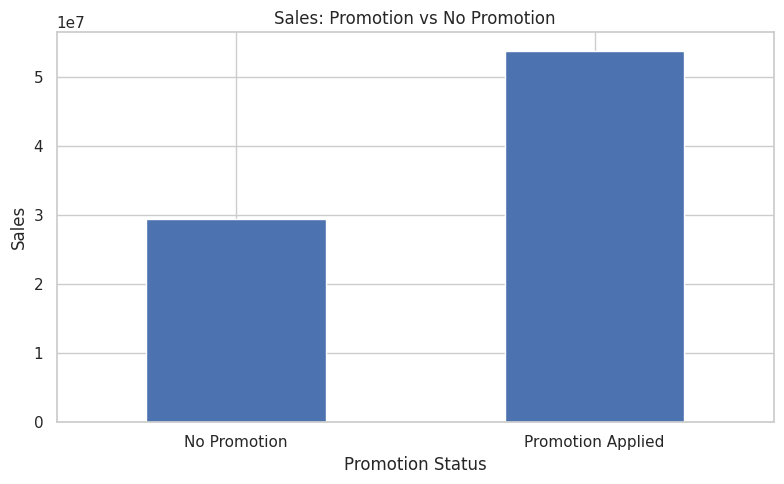

STEP 20 COMPLETED!


In [ ]:

# STEP 20: PROMOTION ANALYSIS

if "promotion_ids" in df.columns:
    promotion_text = df["promotion_ids"].astype("string").str.strip()

    df["has_promotion"] = (
        df["promotion_ids"].notna()
        & promotion_text.ne("")
        & promotion_text.str.lower().ne("nan")
    )

    promotion_summary = df.groupby("has_promotion")["amount"].agg(
        Record_Count="count",
        Total_Sales="sum",
        Average_Amount="mean"
    )

    promotion_summary.index = promotion_summary.index.map({
        True: "Promotion Applied",
        False: "No Promotion"
    })

    print("Promotion summary:")
    display(promotion_summary)

    promotion_summary["Total_Sales"].plot(kind="bar", figsize=(8, 5))
    plt.title("Sales: Promotion vs No Promotion")
    plt.xlabel("Promotion Status")
    plt.ylabel("Sales")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("Promotion column not found.")

print("STEP 20 COMPLETED!")


In [ ]:

# STEP 21: CURRENCY ANALYSIS

if "currency" in df.columns:
    print("Currency distribution:")
    display(df["currency"].value_counts(dropna=False).rename("Records").reset_index())

    print("\nSales by currency:")
    display(
        df.groupby("currency", dropna=False)["amount"]
        .sum()
        .rename("Sales")
        .reset_index()
    )
else:
    print("Currency column not found. Check the dataset's currency before labeling sales.")

print("STEP 21 COMPLETED!")


Currency distribution:


,currency,Records
0,INR,121152
1,NaN,7791



Sales by currency:


,currency,Sales
0,INR,78572537.94
1,NaN,4713555.00


STEP 21 COMPLETED!


TOP 10 CITIES BY SALES


,ship_city,Total Sales
0,BENGALURU,7167740.99
1,HYDERABAD,5227277.82
2,MUMBAI,3859728.80
3,NEW DELHI,3821817.78
4,CHENNAI,3273076.74
5,PUNE,2457729.18
6,KOLKATA,1497258.87
7,GURUGRAM,1272493.74
8,THANE,1061225.29
9,LUCKNOW,996846.34


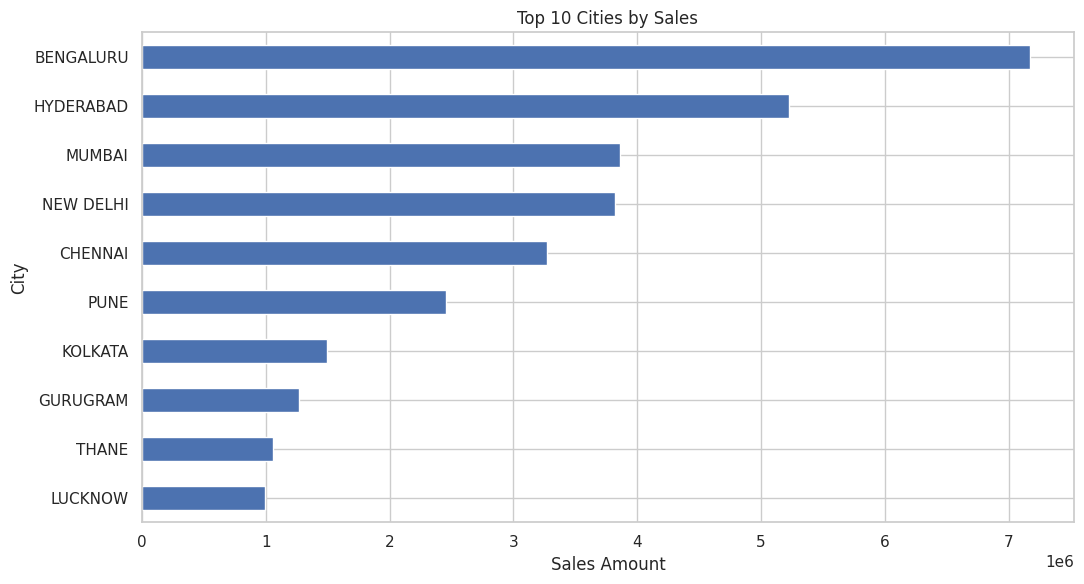

STEP 22 COMPLETED!


In [ ]:

# STEP 22: CITY-WISE SALES ANALYSIS

if "ship_city" in df.columns:
    city_sales = (
        df.groupby("ship_city")["amount"]
        .sum()
        .sort_values(ascending=False)
        .head(10)
    )

    print("TOP 10 CITIES BY SALES")
    display(city_sales.rename("Total Sales").reset_index())

    city_sales.sort_values().plot(kind="barh", figsize=(11, 6))
    plt.title("Top 10 Cities by Sales")
    plt.xlabel("Sales Amount")
    plt.ylabel("City")
    plt.tight_layout()
    plt.show()
else:
    print("City column not found.")

print("STEP 22 COMPLETED!")



AMOUNT OUTLIER SUMMARY
----------------------------------------
Minimum value: 0.00
Maximum value: 5,584.00
Q1: 459.00
Q3: 771.00
Lower boundary: -9.00
Upper boundary: 1,239.00
Outlier count: 4,177
Outlier percentage: 3.24%


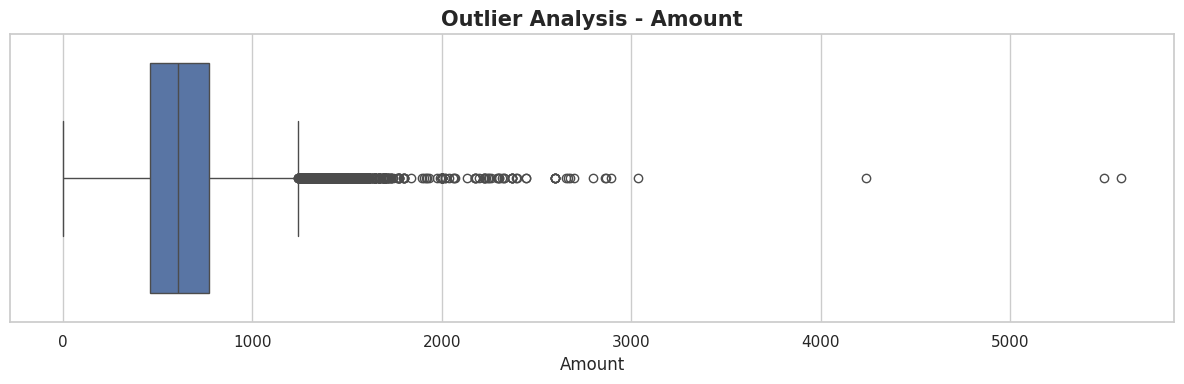

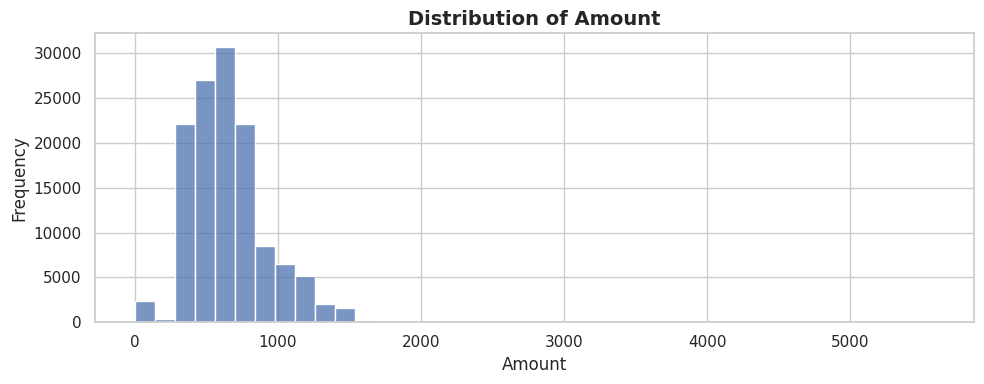


QTY OUTLIER SUMMARY
----------------------------------------
Minimum value: 0.00
Maximum value: 15.00
Q1: 1.00
Q3: 1.00
Lower boundary: 1.00
Upper boundary: 1.00
Outlier count: 13,195
Outlier percentage: 10.23%


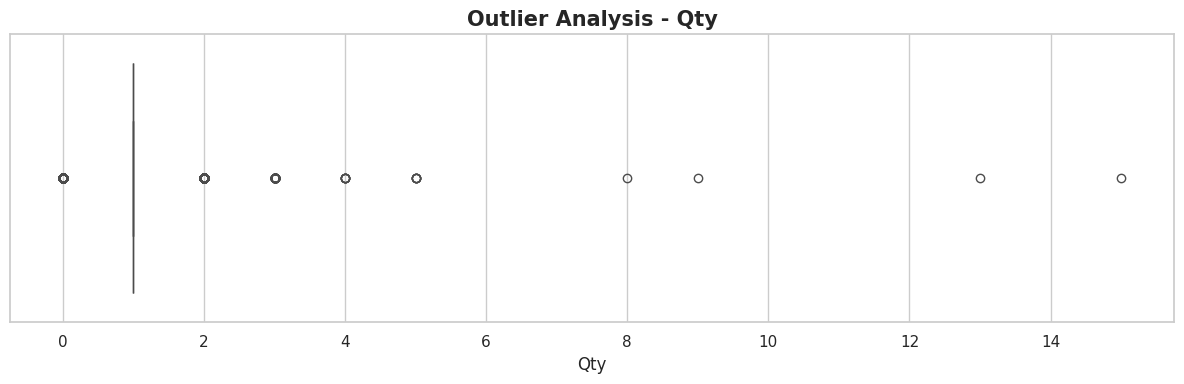

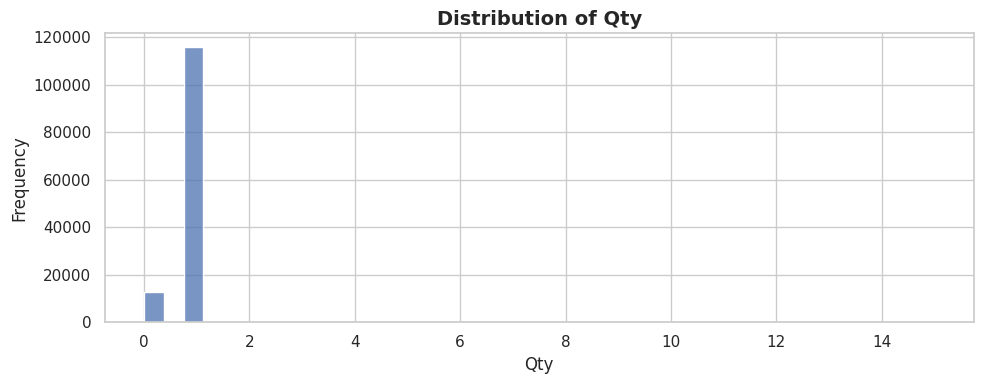


STEP 23 COMPLETED SUCCESSFULLY!


In [ ]:

# ============================================================
# STEP 23: OUTLIER ANALYSIS - IMPROVED
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

for col in ["amount", "qty"]:

    if col not in df.columns:
        print(f"{col} column not found. Skipping.")
        continue

    values = pd.to_numeric(df[col], errors="coerce").dropna()

    if values.empty:
        print(f"No valid numeric values for {col}.")
        continue

    # Calculate IQR boundaries
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = values[
        (values < lower_bound) |
        (values > upper_bound)
    ]

    print(f"\n{col.upper()} OUTLIER SUMMARY")
    print("-" * 40)
    print(f"Minimum value: {values.min():,.2f}")
    print(f"Maximum value: {values.max():,.2f}")
    print(f"Q1: {Q1:,.2f}")
    print(f"Q3: {Q3:,.2f}")
    print(f"Lower boundary: {lower_bound:,.2f}")
    print(f"Upper boundary: {upper_bound:,.2f}")
    print(f"Outlier count: {len(outliers):,}")
    print(f"Outlier percentage: {len(outliers) / len(values) * 100:.2f}%")

    # Improved box plot
    plt.figure(figsize=(12, 4))
    sns.boxplot(x=values, showfliers=True)

    plt.title(
        f"Outlier Analysis - {col.title()}",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel(col.title())
    plt.tight_layout()
    plt.show()

    # Histogram for distribution
    plt.figure(figsize=(10, 4))
    sns.histplot(values, bins=40)

    plt.title(
        f"Distribution of {col.title()}",
        fontsize=14,
        fontweight="bold"
    )
    plt.xlabel(col.title())
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

print("\nSTEP 23 COMPLETED SUCCESSFULLY!")



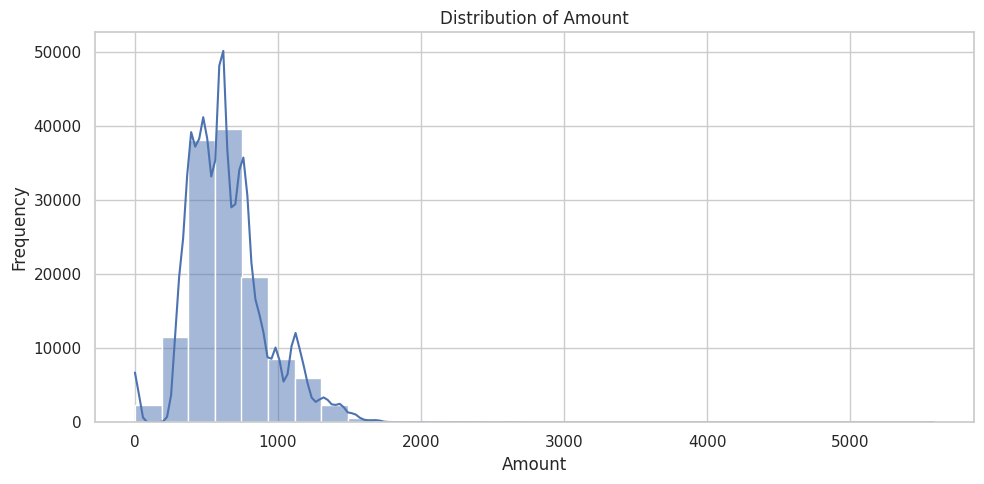

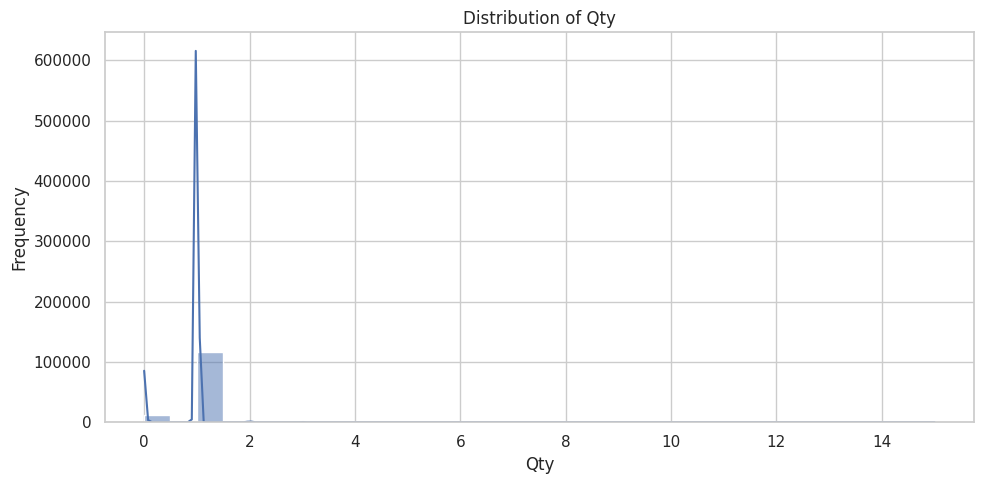

STEP 24 COMPLETED!


In [ ]:

# STEP 24: DISTRIBUTION ANALYSIS

for col in ["amount", "qty"]:
    if col in df.columns:
        values = df[col].dropna()

        if not values.empty:
            plt.figure(figsize=(10, 5))
            sns.histplot(values, bins=30, kde=True)
            plt.title(f"Distribution of {col.title()}")
            plt.xlabel(col.title())
            plt.ylabel("Frequency")
            plt.tight_layout()
            plt.show()

print("STEP 24 COMPLETED!")


Correlation matrix:


,amount,qty
amount,1.000000,0.072924
qty,0.072924,1.000000


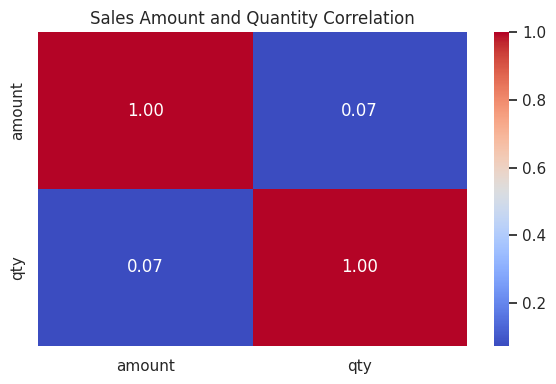

STEP 25 COMPLETED!


In [ ]:

# STEP 25: CORRELATION ANALYSIS

numeric_cols = [
    col for col in ["amount", "qty"]
    if col in df.columns
]

if len(numeric_cols) >= 2:
    correlation = df[numeric_cols].corr()

    print("Correlation matrix:")
    display(correlation)

    plt.figure(figsize=(6, 4))
    sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title("Sales Amount and Quantity Correlation")
    plt.tight_layout()
    plt.show()
else:
    print("Both amount and qty columns are needed.")

print("STEP 25 COMPLETED!")


,date,qty
0,2022-03-01,156
1,2022-04-01,44210
2,2022-05-01,38014
3,2022-06-01,34268


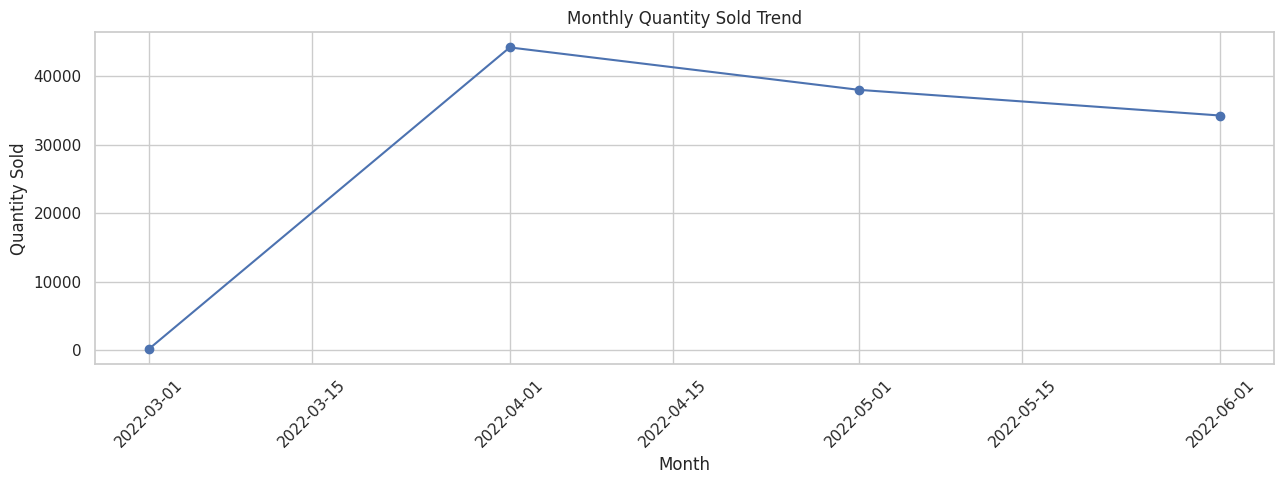

STEP 26 COMPLETED!


In [ ]:

# STEP 26: MONTHLY QUANTITY TREND

if "date" in df.columns and "qty" in df.columns:
    valid_dates = df.dropna(subset=["date"]).copy()

    monthly_quantity = (
        valid_dates.groupby(valid_dates["date"].dt.to_period("M"))["qty"]
        .sum()
        .reset_index()
    )

    monthly_quantity["date"] = monthly_quantity["date"].dt.to_timestamp()

    display(monthly_quantity)

    if not monthly_quantity.empty:
        plt.figure(figsize=(13, 5))
        plt.plot(
            monthly_quantity["date"],
            monthly_quantity["qty"],
            marker="o"
        )
        plt.title("Monthly Quantity Sold Trend")
        plt.xlabel("Month")
        plt.ylabel("Quantity Sold")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
else:
    print("Date or quantity column not found.")

print("STEP 26 COMPLETED!")


YEARLY SALES


,date,Sales
0,2022,83286092.94


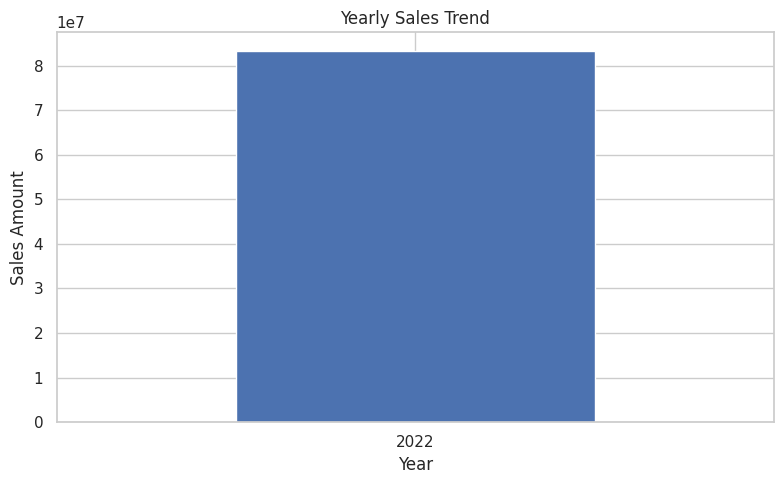

STEP 27 COMPLETED!


In [ ]:

# STEP 27: YEARLY SALES TREND

if "date" in df.columns and "amount" in df.columns:
    valid_dates = df.dropna(subset=["date"]).copy()

    yearly_sales = (
        valid_dates.groupby(valid_dates["date"].dt.year)["amount"]
        .sum()
    )

    print("YEARLY SALES")
    display(yearly_sales.rename("Sales").reset_index())

    if not yearly_sales.empty:
        yearly_sales.plot(kind="bar", figsize=(8, 5))
        plt.title("Yearly Sales Trend")
        plt.xlabel("Year")
        plt.ylabel("Sales Amount")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()
else:
    print("Date or amount column not found.")

print("STEP 27 COMPLETED!")


SALES BY DAY TYPE


,day_type,Sales
0,Weekday,58600131.43
1,Weekend,24685961.51


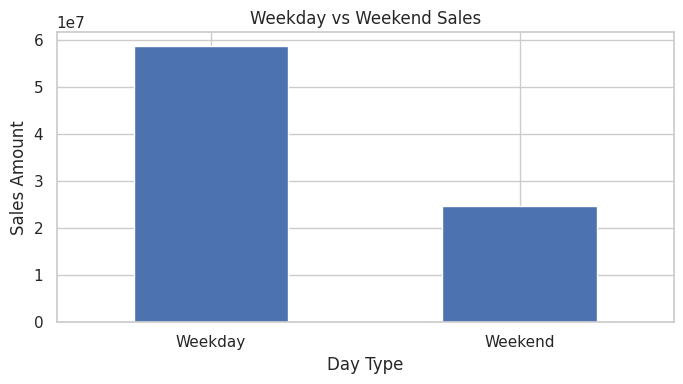

STEP 28 COMPLETED!


In [ ]:

# STEP 28: WEEKDAY VS WEEKEND ANALYSIS

if "date" in df.columns and "amount" in df.columns:
    valid_dates = df.dropna(subset=["date"]).copy()

    valid_dates["day_type"] = np.where(
        valid_dates["date"].dt.dayofweek >= 5,
        "Weekend",
        "Weekday"
    )

    day_type_sales = valid_dates.groupby("day_type")["amount"].sum()

    print("SALES BY DAY TYPE")
    display(day_type_sales.rename("Sales").reset_index())

    day_type_sales.plot(kind="bar", figsize=(7, 4))
    plt.title("Weekday vs Weekend Sales")
    plt.xlabel("Day Type")
    plt.ylabel("Sales Amount")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("Date or amount column not found.")

print("STEP 28 COMPLETED!")


In [ ]:

# STEP 29: FINAL KPI SUMMARY

final_kpis = {
    "Metric": [
        "Total Sales",
        "Total Quantity Sold",
        "Total Unique Orders",
        "Average Order Value",
        "Cancellation Rate (%)",
        "Number of Categories",
        "Number of Products",
        "Number of States",
        "Number of Cities"
    ],
    "Value": [
        df["amount"].sum() if "amount" in df.columns else np.nan,
        df["qty"].sum() if "qty" in df.columns else np.nan,
        df["order_id"].nunique() if "order_id" in df.columns else np.nan,
        average_order_value if "average_order_value" in globals() else np.nan,
        cancellation_rate if "cancellation_rate" in globals() else np.nan,
        df["category"].nunique() if "category" in df.columns else np.nan,
        df["style"].nunique() if "style" in df.columns else np.nan,
        df["ship_state"].nunique() if "ship_state" in df.columns else np.nan,
        df["ship_city"].nunique() if "ship_city" in df.columns else np.nan
    ]
}

final_kpi_table = pd.DataFrame(final_kpis)

print("FINAL BUSINESS KPI SUMMARY")
display(final_kpi_table)

print("STEP 29 COMPLETED!")


FINAL BUSINESS KPI SUMMARY


,Metric,Value
0,Total Sales,8.328609e+07
1,Total Quantity Sold,1.166480e+05
2,Total Unique Orders,1.203520e+05
3,Average Order Value,6.920208e+02
4,Cancellation Rate (%),1.422179e+01
5,Number of Categories,9.000000e+00
6,Number of Products,1.377000e+03
7,Number of States,6.900000e+01
8,Number of Cities,8.955000e+03


STEP 29 COMPLETED!


In [ ]:

# STEP 30: FINAL DATA QUALITY CHECK

print("FINAL DATASET SHAPE:", df.shape)

print("\nDuplicate rows remaining:", df.duplicated().sum())

print("\nMissing values by column:")
display(df.isnull().sum().rename("Missing Values").reset_index())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows of the cleaned dataset:")
display(df.head())

print("STEP 30 COMPLETED!")


FINAL DATASET SHAPE: (128943, 25)

Duplicate rows remaining: 0

Missing values by column:


,index,Missing Values
0,order_id,0
1,date,0
2,status,0
3,fulfilment,0
4,sales_channel,0
5,ship_service_level,0
6,style,0
7,sku,0
8,category,0
9,size,0



Data types:
order_id                      object
date                  datetime64[ns]
status                        object
fulfilment                    object
sales_channel                 object
ship_service_level            object
style                         object
sku                           object
category                      object
size                          object
asin                          object
courier_status                object
qty                            int64
currency                      object
amount                       float64
ship_city                     object
ship_state                    object
ship_postal_code             float64
ship_country                  object
promotion_ids                 object
b2b                             bool
fulfilled_by                  object
unnamed_22                    object
customer_type                 object
has_promotion                boolean
dtype: object

First 5 rows of the cleaned dataset:


,order_id,date,status,fulfilment,sales_channel,ship_service_level,style,sku,category,size,asin,courier_status,qty,currency,amount,ship_city,ship_state,ship_postal_code,ship_country,promotion_ids,b2b,fulfilled_by,unnamed_22,customer_type,has_promotion
0,405-8078784-5731545,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,S,B09KXVBD7Z,NaN,0,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN,B2C,False
1,171-9198151-1101146,2022-04-30,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,3XL,B09K3WFS32,Shipped,1,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN,B2C,True
2,404-0687676-7273146,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,XL,B07WV4JV4D,Shipped,1,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN,B2B,True
3,403-9615377-8133951,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,L,B099NRCT7B,NaN,0,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN,B2C,False
4,407-1069790-7240320,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,3XL,B098714BZP,Shipped,1,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN,B2C,False


STEP 30 COMPLETED!


In [ ]:

# STEP 31: AUTOMATIC KEY INSIGHTS

print("=" * 55)
print("KEY BUSINESS INSIGHTS")
print("=" * 55)

print(f"1. The cleaned dataset contains {len(df):,} records.")

if "amount" in df.columns:
    print(f"2. Total recorded sales: {df['amount'].sum():,.2f}")

if "order_id" in df.columns:
    print(f"3. Unique orders: {df['order_id'].nunique():,}")

if "qty" in df.columns:
    print(f"4. Total quantity sold: {df['qty'].sum():,.0f}")

if "category" in df.columns and "amount" in df.columns:
    category_totals = df.groupby("category")["amount"].sum()
    if not category_totals.empty:
        print(f"5. Highest-sales category: {category_totals.idxmax()}")

if "style" in df.columns and "amount" in df.columns:
    product_totals = df.groupby("style")["amount"].sum()
    if not product_totals.empty:
        print(f"6. Highest-sales product/style: {product_totals.idxmax()}")

if "ship_state" in df.columns and "amount" in df.columns:
    state_totals = df.groupby("ship_state")["amount"].sum()
    if not state_totals.empty:
        print(f"7. Highest-sales state: {state_totals.idxmax()}")

if "status" in df.columns:
    cancelled = df["status"].astype("string").str.contains(
        "cancel", case=False, na=False
    )
    rate = cancelled.mean() * 100 if len(df) else 0
    print(f"8. Records marked cancelled: {rate:.2f}%")

print("\nSTEP 31 COMPLETED!")


KEY BUSINESS INSIGHTS
1. The cleaned dataset contains 128,943 records.
2. Total recorded sales: 83,286,092.94
3. Unique orders: 120,352
4. Total quantity sold: 116,648
5. Highest-sales category: Set
6. Highest-sales product/style: JNE3797
7. Highest-sales state: MAHARASHTRA
8. Records marked cancelled: 14.22%

STEP 31 COMPLETED!


In [ ]:

# STEP 32: RECOMMENDATIONS AND CONCLUSION

print("=" * 55)
print("BUSINESS RECOMMENDATIONS")
print("=" * 55)

recommendations = [
    "1. Inventory Planning: Monitor high-demand products and maintain suitable stock.",
    "2. Sales Strategy: Study top-performing categories and products.",
    "3. Geographic Strategy: Evaluate sales patterns across states and cities.",
    "4. Order Management: Investigate cancellation patterns and order statuses.",
    "5. Fulfillment: Review shipping methods and fulfillment performance.",
    "6. Promotions: Compare promoted and non-promoted sales carefully.",
    "7. Customer Analysis: Compare B2B and B2C purchasing behavior.",
    "8. KPI Monitoring: Track sales, orders, quantity, and cancellation trends."
]

for recommendation in recommendations:
    print(recommendation)

print("\n" + "=" * 55)
print("PROJECT CONCLUSION")
print("=" * 55)

print("""
This project performed exploratory data analysis on e-commerce
sales data using Python in Google Colab.

The analysis included data cleaning, KPI calculations, monthly
and yearly sales trends, product and category performance,
geographic sales, customer types, sales channels, cancellations,
fulfillment, promotions, and numerical distributions.

The findings help identify business patterns and potential
areas for improvement in inventory, sales, customer targeting,
and order management.

Recommendations should be validated against the actual results
before business decisions are made.
""")

print("STEP 32 COMPLETED!")


BUSINESS RECOMMENDATIONS
1. Inventory Planning: Monitor high-demand products and maintain suitable stock.
2. Sales Strategy: Study top-performing categories and products.
3. Geographic Strategy: Evaluate sales patterns across states and cities.
4. Order Management: Investigate cancellation patterns and order statuses.
5. Fulfillment: Review shipping methods and fulfillment performance.
6. Promotions: Compare promoted and non-promoted sales carefully.
7. Customer Analysis: Compare B2B and B2C purchasing behavior.
8. KPI Monitoring: Track sales, orders, quantity, and cancellation trends.

PROJECT CONCLUSION

This project performed exploratory data analysis on e-commerce
sales data using Python in Google Colab.

The analysis included data cleaning, KPI calculations, monthly
and yearly sales trends, product and category performance,
geographic sales, customer types, sales channels, cancellations,
fulfillment, promotions, and numerical distributions.

The findings help identify business pat

In [ ]:

# STEP 33: SAVE CLEANED DATASET

output_path = "/content/cleaned_sales_dataset.csv"

df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", output_path)

# Verify that the file exists
import os

print("File exists:", os.path.exists(output_path))
print("File size:", f"{os.path.getsize(output_path):,} bytes")


Cleaned dataset saved successfully!
File location: /content/cleaned_sales_dataset.csv
File exists: True
File size: 69,624,005 bytes
